# Phase 7: testing forecasts on past data

From every day of the last 3 years, each forecast predicts the next 1–14 days using only prices known that day. It is then compared with what NECC actually published. These simple forecasts are the bar the Phase 8 models have to beat:

- **same price**: the price stays as it is today
- **last year's change**: today's price moved by last year's % change over the same days
- **5-year average change**: today's price moved by the average % change over the same days in the last 5 years

Two measures for each day ahead: the average error in ₹ (per 100 eggs), and how often a ₹10 range centred on the forecast (545–555 for 550) contained the actual price.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import backtest
from eggdata import app_zones, zone_prices

prices = zone_prices()
zones = app_zones()
NAMES = dict(zip(zones.id, zones.name))
days = backtest.origins(prices, years=3)
scored = {name: backtest.score(rows) for name, rows in backtest.simple_forecasts(prices, days).items()}
pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.dpi": 96, "axes.grid": True, "grid.alpha": 0.3})
print(f"{len(days)} forecast days, {days[0]:%d %b %Y} to {days[-1]:%d %b %Y}; "
      f"{len(scored['same price']):,} forecasts for each method")

1082 forecast days, 27 Oct 2023 to 12 Oct 2026; 106,036 forecasts for each method


## Each day ahead

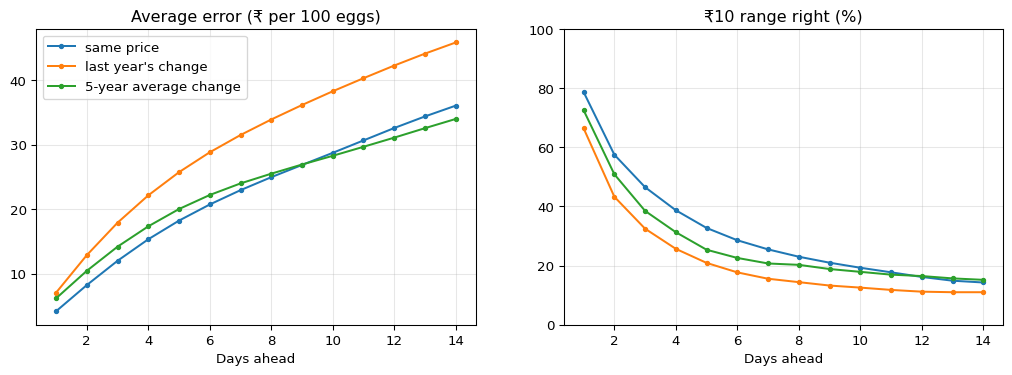

same price       last year's change       5-year average change  \
              error ₹ hit %            error ₹ hit %               error ₹   
days ahead                                                                   
1                 4.2  78.7                7.1  66.4                   6.2   
2                 8.3  57.5               12.9  43.3                  10.5   
3                12.0  46.5               17.9  32.5                  14.2   
4                15.4  38.7               22.2  25.7                  17.4   
5                18.2  32.7               25.7  20.9                  20.0   
6                20.7  28.6               28.8  17.7                  22.2   
7                23.0  25.5               31.5  15.6                  24.0   
8                25.0  23.0               33.9  14.4                  25.5   
9                26.9  21.0               36.1  13.3                  26.9   
10               28.7  19.3               38.3  12.6                  28.3   
11               30.7  17.7               40.3  11.8                  29.7   
12               32.6  16.2               42.2  11.2                  31.1   
13               34.4  14.9               44.1  11.0                  32.5   
14               36.0  14.3               45.8  11.0                  34.0   

                  
           hit %  
days ahead        
1           72.6  
2           50.9  
3           38.5  
4           31.3  
5           25.4  
6           22.6  
7           20.7  
8           20.3  
9           18.8  
10          17.9  
11          16.9  
12          16.5  
13          15.7  
14          15.2

In [2]:
summary = backtest.by_horizon(scored)
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
for name in scored:
    left.plot(summary.index, summary[(name, "error ₹")], marker="o", ms=3, label=name)
    right.plot(summary.index, summary[(name, "hit %")], marker="o", ms=3, label=name)
left.set(title="Average error (₹ per 100 eggs)", xlabel="Days ahead")
right.set(title="₹10 range right (%)", xlabel="Days ahead", ylim=(0, 100))
left.legend()
plt.show()
summary.round(1)

## Each zone

1, 7 and 14 days ahead for each method, then every day ahead for "same price".

In [3]:
print("₹10 range right (%)")
display(backtest.by_zone(scored, "hit %").rename(index=NAMES).round(0))
print("Average error (₹)")
display(backtest.by_zone(scored, "error ₹").rename(index=NAMES).round(1))
same = scored["same price"]
print("Same price: ₹10 range right (%) by zone and day ahead")
(same.groupby(["zone", "h"]).hit.mean().unstack() * 100).rename(index=NAMES).round(0)

₹10 range right (%)


same price             last year's change              \
                  1 d   7 d  14 d                1 d   7 d  14 d   
zone                                                               
Bengaluru        84.0  33.0  17.0               74.0  20.0  10.0   
Chennai          77.0  27.0  13.0               62.0  13.0  10.0   
Chittoor         77.0  28.0  13.0               62.0  13.0  10.0   
Hyderabad        85.0  22.0  17.0               76.0  17.0  11.0   
Kolkata          66.0  16.0  13.0               50.0  12.0  12.0   
Namakkal         86.0  35.0  17.0               77.0  20.0  13.0   
Vijayawada       75.0  18.0  10.0               65.0  14.0  11.0   

           5-year average change              
                             1 d   7 d  14 d  
zone                                          
Bengaluru                   78.0  24.0  18.0  
Chennai                     74.0  20.0  15.0  
Chittoor                    74.0  20.0  15.0  
Hyderabad                   74.0  19.0  15.0  
Kolkata                     59.0  17.0  13.0  
Namakkal                    78.0  26.0  17.0  
Vijayawada                  70.0  20.0  14.0

Average error (₹)


same price             last year's change              \
                  1 d   7 d  14 d                1 d   7 d  14 d   
zone                                                               
Bengaluru         3.5  21.1  35.1                6.0  29.5  45.3   
Chennai           3.6  22.4  36.6                6.3  31.8  47.9   
Chittoor          3.5  22.2  36.3                6.3  31.5  47.5   
Hyderabad         4.5  23.8  36.2                7.1  31.4  46.6   
Kolkata           6.2  26.5  37.1               10.4  36.0  45.3   
Namakkal          3.2  19.6  33.6                5.5  27.7  43.0   
Vijayawada        4.9  25.1  37.2                7.9  32.6  45.0   

           5-year average change              
                             1 d   7 d  14 d  
zone                                          
Bengaluru                    5.3  22.3  32.2  
Chennai                      5.8  23.7  34.8  
Chittoor                     5.8  23.6  34.5  
Hyderabad                    6.3  24.2  34.0  
Kolkata                      8.4  27.4  35.4  
Namakkal                     5.1  21.1  32.0  
Vijayawada                   6.8  25.7  34.9

Same price: ₹10 range right (%) by zone and day ahead


h,1,2,3,4,5,6,7,8,9,10,11,12,13,14
zone,,,,,,,,,,,,,,
Bengaluru,84.0,64.0,55.0,48.0,42.0,37.0,33.0,29.0,26.0,24.0,21.0,19.0,17.0,17.0
Chennai,77.0,62.0,51.0,43.0,37.0,31.0,27.0,24.0,21.0,19.0,17.0,15.0,13.0,13.0
Chittoor,77.0,62.0,52.0,44.0,37.0,32.0,28.0,24.0,21.0,19.0,17.0,15.0,13.0,13.0
Hyderabad,85.0,53.0,41.0,32.0,26.0,22.0,22.0,21.0,20.0,20.0,20.0,19.0,18.0,17.0
Kolkata,66.0,40.0,27.0,21.0,17.0,16.0,16.0,16.0,17.0,16.0,14.0,14.0,13.0,13.0
Namakkal,86.0,68.0,59.0,52.0,45.0,40.0,35.0,31.0,28.0,25.0,23.0,20.0,18.0,17.0
Vijayawada,75.0,53.0,41.0,31.0,25.0,22.0,18.0,15.0,13.0,13.0,13.0,12.0,11.0,10.0


## Findings (forecasts made 27 Oct 2023 to 12 Oct 2026)

- **Same price** is the hardest simple forecast to beat for the first 9 days. Its average error grows from ₹4 at 1 day to ₹23 at 7 days and ₹36 at 14 days. Its ₹10 range is right 79% of the time at 1 day, 26% at 7 days and 14% at 14 days.
- **5-year average change** has a slightly smaller error from day 10 (₹34 against ₹36 at 14 days) and a slightly better ₹10 hit rate from day 13: the yearly pattern helps over longer spans.
- **Last year's change** is the worst at every day ahead; one year's moves are too noisy to copy.
- **By zone:** Kolkata is the hardest (66% right at 1 day, 16% at 7 days). Namakkal and Bengaluru are the easiest (84–86% at 1 day, 33–35% at 7 days).
- **The bar for Phase 8:** a smaller error than same price at every day ahead, and than the 5-year average change for days 10–14.